# 38b. Pooled calibration: supervised common-frame equivariance (one-window training)

Follow-up to notebook 38. **The positive/negative prior-difference loss is removed.** Each independent 5-second window receives one physical augmentation and **one** sampled erroneous calibration. The exact same measurements, erroneous prior, and reference calibration are then expressed in two common/body coordinate frames, linked by a single rotation-only transform \(H_G\). Both views receive ordinary supervised calibration loss; their predicted corrections additionally receive an SO(3)/SE(3)/time-offset equivariance loss.

This is **not BPTT** and uses the same KAIST splits, pooled Transformer, regression scales, pretrained checkpoint, one-window optimizer and validation/checkpoint conventions as notebook 38. The reference and transformed views share all physical samples and random calibration errors. Only their coordinate representation differs.

\[
T'_{B,S}=H_G T_{B,S},\quad \widehat{\delta\xi}'_{S}\approx\mathrm{Ad}_{H_G}\widehat{\delta\xi}_{S},\quad \widehat{\delta\tau}'_{S}\approx\widehat{\delta\tau}_{S}.
\]

For \(H_G=[G,0;0,1]\), \(\mathrm{Ad}_{H_G}=\mathrm{diag}(G,G)\) on the six-dimensional twist. Zero predictions would satisfy the equivariance term alone, hence **both views remain supervised**.

**Preflight:** the new `obscalib.augmentations.common_body_frame` module and its pipeline integration from notebook 38 must already be installed. The common-frame stage in the *physical augmentation pipeline* is disabled intentionally; a separately sampled transform creates the paired view explicitly.

## 1. Imports and repository root

In [41]:
from pathlib import Path
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

ROOT = Path.cwd()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / "src" / "obscalib").exists():
        ROOT = candidate
        break
else:
    raise FileNotFoundError("Could not locate the nn-obs-calib repository root containing src/obscalib.")

if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from kaist_dataset.dataset import KAISTCalibrationDataset, KAISTRigCalibration, build_kaist_sequence_specs, make_kaist_dataloader
from obscalib.augmentations.config import AugmentationConfig, CalibrationEventConfig, CommonBodyFrameRandomizationConfig, FrameRandomizationConfig, NoiseAugmentationConfig, PerturbationMagnitudeConfig, PriorPerturbationConfig, SamplingRateAugmentationConfig, TrueCalibrationAugmentationConfig
from obscalib.augmentations.pipeline import AugmentationPipeline
from obscalib.augmentations import PerturbationDistribution
from obscalib.augmentations.prior_perturbation import CalibrationPriorPerturber, apply_prior_perturbation
from obscalib.calibration.state import CalibrationState
from obscalib.calibration.update import CalibrationUpdater
from obscalib.config import CalibrationPoolerConfig, MLPConfig, PooledCalibrationHeadConfig, PooledCalibrationModelConfig, TransformerConfig, WindowingConfig
from obscalib.data.collation import collate_windows
from obscalib.data.device import window_batch_to
from obscalib.data.structures import WindowBatch
from obscalib.geometry.lie import se3_log
from obscalib.geometry.processing import GeometryProcessor
from obscalib.models.pooled_calibration_model import PooledCalibrationModel
from obscalib.pipeline.window_step import WindowStep
from obscalib.tokenization.tokenizer import Tokenizer
from obscalib.training.checkpoint import load_training_checkpoint, save_training_checkpoint
from obscalib.training.metrics_logger import MetricsLogger
import gc

print("Repository root:", ROOT)
print("PyTorch:", torch.__version__)


Repository root: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib
PyTorch: 2.7.1+cu126


## 2. Independent-window experiment configuration

In [63]:
RUN_NAME = "kaist_pooled_calibration_paired_002.20_common_frame_equivariance"

# Specify the exact previous successful checkpoint; this is a weights-only initialization.
# Change SOURCE_RUN_NAME to "kaist_pooled_calibration_paired_002.9_student" if that is your actual saved run directory.
SOURCE_RUN_NAME = "kaist_pooled_calibration_paired_002.16_correction_only"
RESUME_CHECKPOINT = ROOT / "runs" / SOURCE_RUN_NAME / "best.pt"

RANDOM_SEED = 12345
TRAIN_PAIR_SEED = 23456
VALIDATION_PAIR_SEED = 34567
TEST_PAIR_SEED = 45678
VISUALIZATION_PAIR_SEED = 56789

DEVICE_NAME = "cuda"
DEVICE = torch.device("cuda" if DEVICE_NAME == "auto" and torch.cuda.is_available() else DEVICE_NAME)
MODEL_DTYPE = torch.float32

CALIBRATION_KEYS = ("imu", "lidar", "lidar_right")
CALIBRATION_CONTEXT_DIM = 7

WINDOW_DURATION_S = 5.0
WINDOW_STRIDE_S = 5.0
MAX_SAMPLES_PER_SENSOR = 700

BATCH_SIZE = 16
NUM_WORKERS = 0
DROP_LAST_TRAIN = True

NUM_EPOCHS = 200
LEARNING_RATE = 1e-5
WEIGHT_DECAY = 1e-4
GRADIENT_CLIP_NORM = 1.0
CHECKPOINT_EVERY_EPOCHS = 3
PRINT_EVERY_BATCHES = 500
LR_REDUCTION_FACTOR = 0.5
LR_PATIENCE_EPOCHS = 8

MEASUREMENT_DIM = 6
TOKEN_INPUT_DIM = MEASUREMENT_DIM + 2
D_MODEL = 128
N_HEADS = 8
NUM_TRANSFORMER_LAYERS = 12
DIM_FEEDFORWARD = 512
TRANSFORMER_DROPOUT = 0.0
NUM_SUMMARY_TOKENS = 1

POOLER_N_HEADS = 8
POOLER_DROPOUT = 0.0
MLP_HIDDEN_DIMS = (256, 128)
SHARED_FEATURE_DIM = 128
MLP_DROPOUT = 0.0
HEAD_HIDDEN_DIMS = (128, 64)
HEAD_DROPOUT = 0.0

CORRECTION_LOSS_TYPE = "mse"
ROTATION_LOSS_SCALE_RAD = np.deg2rad(5.0)
TRANSLATION_LOSS_SCALE_M = 0.05
TIME_OFFSET_LOSS_SCALE_S = 0.050
ROTATION_LOSS_WEIGHT = 2.0
TRANSLATION_LOSS_WEIGHT = 1.0
TIME_OFFSET_LOSS_WEIGHT = 1.0
EQUIVARIANCE_LOSS_WEIGHT = 0.1  # Tune only after examining equivariance AND both supervised-view errors

CHANGE_EVENT_LOSS_WEIGHT = 0.0
CHANGE_TIME_LOSS_WEIGHT = 0.0

# One paired-prior distribution for every example; no fine/coarse branch.
PAIR_ROTATION_MAX_RAD = np.deg2rad(60.0)
PAIR_ROTATION_SCALE_RAD = np.deg2rad(30.0)
PAIR_TIME_OFFSET_MAX_S = 0.500
PAIR_TIME_OFFSET_SCALE_S = 0.250
STUDENT_T_DEGREES_OF_FREEDOM = 3
PAIR_TRANSLATION_MAX_M = 0.02  # Legacy disabled generic-prior config only.

# Physically consistent true-calibration augmentation, independent of the prior error.
TRUE_CALIBRATION_ROTATION_MAX_RAD = np.deg2rad(180.0)
TRUE_CALIBRATION_TIME_OFFSET_MAX_S = 0.030

# New shared-body-frame augmentation. Set to 0.0 for the control ablation.
COMMON_BODY_FRAME_PROBABILITY = 0.9  # Probability that the second view uses a nonidentity Haar SO(3) frame

if not RESUME_CHECKPOINT.is_file():
    raise FileNotFoundError(f"Source checkpoint not found: {RESUME_CHECKPOINT}. Set SOURCE_RUN_NAME to the saved successful run.")

torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print("Run:", RUN_NAME)
print("One-window frame-equivariance training (BPTT disabled); rotated-view probability:", COMMON_BODY_FRAME_PROBABILITY)
print("Initializing from:", RESUME_CHECKPOINT)
print("Calibration order:", CALIBRATION_KEYS)
print(f"Single prior: rotation maximum={np.rad2deg(PAIR_ROTATION_MAX_RAD):g}°, Student-t scale={np.rad2deg(PAIR_ROTATION_SCALE_RAD):g}°")
print(f"Single prior: tau maximum={PAIR_TIME_OFFSET_MAX_S * 1000:g} ms, Student-t scale={PAIR_TIME_OFFSET_SCALE_S * 1000:g} ms")
print(f"True calibration: rotation maximum={np.rad2deg(TRUE_CALIBRATION_ROTATION_MAX_RAD):g}°, tau maximum={TRUE_CALIBRATION_TIME_OFFSET_MAX_S * 1000:g} ms")

print("Equivariance weight:", EQUIVARIANCE_LOSS_WEIGHT)


Run: kaist_pooled_calibration_paired_002.20_common_frame_equivariance
One-window frame-equivariance training (BPTT disabled); rotated-view probability: 0.9
Initializing from: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_paired_002.16_correction_only/best.pt
Calibration order: ('imu', 'lidar', 'lidar_right')
Single prior: rotation maximum=60°, Student-t scale=30°
Single prior: tau maximum=500 ms, Student-t scale=250 ms
True calibration: rotation maximum=180°, tau maximum=30 ms
Equivariance weight: 0.1


## 3. KAIST splits and DataLoaders (unchanged from notebook 38)

In [43]:
KAIST_DATASET_ROOT = Path("/mnt/d/Downloads/MobRobLab/KAISTDataset")
LIDAR_POSE_ROOT = Path("/home/camel/Skoltech/phd_proposal/data/KAISTDataset")

TRAIN_NAMES = ["Urban08", "Urban12", "Urban13", "Urban14", "Urban15", "Urban16"]
VAL_NAMES = ["Urban26", "Urban28"]
TEST_NAMES = ["Urban38", "Urban39"]
ALL_SEQUENCE_NAMES = TRAIN_NAMES + VAL_NAMES + TEST_NAMES

if len(ALL_SEQUENCE_NAMES) != len(set(ALL_SEQUENCE_NAMES)):
    raise ValueError("Train, validation, and test sequence sets overlap.")

T_B_L = np.array([
    [-0.514066, -0.702201, -0.492595, -0.440699],
    [0.486485, -0.711672, 0.506809, 0.397052],
    [-0.706447, 0.0208933, 0.707457, 1.90953],
    [0.0, 0.0, 0.0, 1.0],
], dtype=float)

# Right LiDAR -> body, in the same convention as T_B_L for the left LiDAR.
T_B_L_right = np.array([
    [-0.512152,  0.699241, -0.498761, -0.449885],
    [-0.494811, -0.714859, -0.494104, -0.416713],
    [-0.702041, -0.0062642, 0.712109,  1.91294],
    [ 0.0,       0.0,       0.0,       1.0],
], dtype=float)

T_I_B = np.array([
    [1.0, 0.0, 0.0, -0.07],
    [0.0, 1.0, 0.0, 0.0],
    [0.0, 0.0, 1.0, 1.7],
    [0.0, 0.0, 0.0, 1.0],
], dtype=float)

rig_calibration = KAISTRigCalibration(T_B_I=np.linalg.inv(T_I_B), T_B_L=T_B_L, tau_imu_s=0.0, tau_lidar_s=0.0, T_B_L_right=T_B_L_right, tau_lidar_right_s=0.0)
windowing_config = WindowingConfig(window_duration_s=WINDOW_DURATION_S, window_stride_s=WINDOW_STRIDE_S, max_samples_per_sensor=MAX_SAMPLES_PER_SENSOR)

print("train:", TRAIN_NAMES)
print("validation:", VAL_NAMES)
print("test:", TEST_NAMES)


train: ['Urban08', 'Urban12', 'Urban13', 'Urban14', 'Urban15', 'Urban16']
validation: ['Urban26', 'Urban28']
test: ['Urban38', 'Urban39']


In [44]:
all_specs = build_kaist_sequence_specs(sequence_names=ALL_SEQUENCE_NAMES, kaist_dataset_root=KAIST_DATASET_ROOT, lidar_pose_root=LIDAR_POSE_ROOT, lidar_right_pose_filename="lidar_map_poses_vlp_right.csv")

# The 3-sensor experiment must never silently fall back to 2 sensors.
for spec in all_specs:
    if spec.lidar_right_pose_csv is None or not spec.lidar_right_pose_csv.is_file():
        raise FileNotFoundError(f"Missing required right-LiDAR pose CSV for {spec.name}: {spec.lidar_right_pose_csv}")
spec_by_name = {spec.name: spec for spec in all_specs}

train_dataset = KAISTCalibrationDataset([spec_by_name[name] for name in TRAIN_NAMES], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)
val_dataset = KAISTCalibrationDataset([spec_by_name[name] for name in VAL_NAMES], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)
test_dataset = KAISTCalibrationDataset([spec_by_name[name] for name in TEST_NAMES], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)

for split_name, dataset in (("train", train_dataset), ("validation", val_dataset), ("test", test_dataset)):
    if tuple(dataset.calibration_keys) != CALIBRATION_KEYS:
        raise AssertionError(f"{split_name} dataset has calibration keys {dataset.calibration_keys}, expected {CALIBRATION_KEYS}")

print(train_dataset.summary())
print()
print(val_dataset.summary())
print()
print(test_dataset.summary())


KAISTCalibrationDataset: 2006 windows from 6 sequences
approximate tensor storage: 44.0 MiB
  Urban08: windows=59, duration=297.8s, IMU=30800, LiDAR=2952, right LiDAR=2953
  Urban12: windows=473, duration=2478.6s, IMU=249198, LiDAR=23222, right LiDAR=23223
  Urban13: windows=223, duration=1446.5s, IMU=145492, LiDAR=10536, right LiDAR=10535
  Urban14: windows=286, duration=1737.0s, IMU=174681, LiDAR=13638, right LiDAR=13639
  Urban15: windows=184, duration=1034.3s, IMU=104795, LiDAR=9011, right LiDAR=9011
  Urban16: windows=781, duration=4458.1s, IMU=449215, LiDAR=37703, right LiDAR=37704

KAISTCalibrationDataset: 418 windows from 2 sequences
approximate tensor storage: 9.2 MiB
  Urban26: windows=94, duration=566.9s, IMU=58371, LiDAR=4553, right LiDAR=4551
  Urban28: windows=324, duration=1958.5s, IMU=197456, LiDAR=15651, right LiDAR=15658

KAISTCalibrationDataset: 699 windows from 2 sequences
approximate tensor storage: 15.4 MiB
  Urban38: windows=349, duration=2147.3s, IMU=216225, LiD

In [45]:
train_shuffle_generator = torch.Generator().manual_seed(RANDOM_SEED)
train_loader = make_kaist_dataloader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=DROP_LAST_TRAIN, num_workers=NUM_WORKERS, generator=train_shuffle_generator)
val_loader = make_kaist_dataloader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=False, num_workers=NUM_WORKERS)
test_loader = make_kaist_dataloader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=False, num_workers=NUM_WORKERS)

print("train batches:", len(train_loader))
print("validation batches:", len(val_loader))
print("test batches:", len(test_loader))


train batches: 125
validation batches: 27
test batches: 44


## 4. Physical augmentation plus **one** calibration prior

Keep true-calibration diversification, but do **not** apply common-body-frame augmentation inside this first stage. It will be applied once to the *already perturbed* window to create the second view, ensuring the physical calibration fault is the same in both coordinate systems. Independent sensor-frame randomization, sampling-rate augmentation, events, and noise retain notebook 38 settings (disabled here).

In [46]:
# Augment one physical installation, then sample one prior; apply common-frame G later to a complete view.
# The generic prior perturbation stays disabled to avoid modifying the shared truth.
context_augmentation_config = AugmentationConfig(
    sampling_rate=SamplingRateAugmentationConfig(enabled=False),
    frame_randomization=FrameRandomizationConfig(enabled=False),
    common_body_frame=CommonBodyFrameRandomizationConfig(enabled=False, probability=0.0),
    true_calibration=TrueCalibrationAugmentationConfig(
        enabled=True,
        probability=1.0,
        rotation_probability=1.0,
        translation_probability=0.0,
        time_offset_probability=1.0,
        rotation=PerturbationMagnitudeConfig(maximum=TRUE_CALIBRATION_ROTATION_MAX_RAD),
        time_offset=PerturbationMagnitudeConfig(maximum=TRUE_CALIBRATION_TIME_OFFSET_MAX_S),
    ),
    prior_perturbation=PriorPerturbationConfig(enabled=False, probability=1.0, rotation=PerturbationMagnitudeConfig(maximum=PAIR_ROTATION_MAX_RAD), translation=PerturbationMagnitudeConfig(maximum=PAIR_TRANSLATION_MAX_M), time_offset=PerturbationMagnitudeConfig(maximum=PAIR_TIME_OFFSET_MAX_S), one_calibration_per_sample=True, one_rotation_axis_per_sample=False),
    calibration_event=CalibrationEventConfig(enabled=False),
    noise=NoiseAugmentationConfig(enabled=False),
)

pair_prior_config = PriorPerturbationConfig(
    enabled=True,
    probability=1.0,
    rotation=PerturbationMagnitudeConfig(maximum=PAIR_ROTATION_MAX_RAD, distribution=PerturbationDistribution.TRUNCATED_STUDENT_T, scale=PAIR_ROTATION_SCALE_RAD, degrees_of_freedom=STUDENT_T_DEGREES_OF_FREEDOM),
    translation=None,
    time_offset=PerturbationMagnitudeConfig(maximum=PAIR_TIME_OFFSET_MAX_S, distribution=PerturbationDistribution.TRUNCATED_STUDENT_T, scale=PAIR_TIME_OFFSET_SCALE_S, degrees_of_freedom=STUDENT_T_DEGREES_OF_FREEDOM),
    one_calibration_per_sample=True,
    one_rotation_axis_per_sample=False,
    one_perturbation_type_per_sample=False,
)

context_augmentation_pipeline = AugmentationPipeline(context_augmentation_config)
pair_prior_perturber = CalibrationPriorPerturber(pair_prior_config)

print("Shared physical/context augmentation:", context_augmentation_config)
print("Paired prior:", pair_prior_config)
print("Common-frame stage disabled in physical pipeline:", context_augmentation_config.common_body_frame)
from obscalib.augmentations.common_body_frame import CommonBodyFrameRandomizer
frame_view_randomizer = CommonBodyFrameRandomizer(CommonBodyFrameRandomizationConfig(enabled=True, probability=COMMON_BODY_FRAME_PROBABILITY))
print("Paired-view randomizer:", frame_view_randomizer.config)


Shared physical/context augmentation: AugmentationConfig(sampling_rate=SamplingRateAugmentationConfig(enabled=False, minimum_imu_frequency_hz=None, minimum_lidar_frequency_hz=None, imu_probability=1.0, lidar_probability=1.0), frame_randomization=FrameRandomizationConfig(enabled=False), prior_perturbation=PriorPerturbationConfig(enabled=False, probability=1.0, probability_by_key={}, rotation=PerturbationMagnitudeConfig(maximum=1.0471975511965976, distribution=<PerturbationDistribution.UNIFORM: 'uniform'>, scale=None, degrees_of_freedom=3), translation=PerturbationMagnitudeConfig(maximum=0.02, distribution=<PerturbationDistribution.UNIFORM: 'uniform'>, scale=None, degrees_of_freedom=3), time_offset=PerturbationMagnitudeConfig(maximum=0.5, distribution=<PerturbationDistribution.UNIFORM: 'uniform'>, scale=None, degrees_of_freedom=3), one_calibration_per_sample=True, one_rotation_axis_per_sample=False, one_perturbation_type_per_sample=False), calibration_event=CalibrationEventConfig(enabled

## 5. Pooled model and complete window pipeline (architecture unchanged)

In [47]:
model_config = PooledCalibrationModelConfig(
    transformer=TransformerConfig(input_dim=TOKEN_INPUT_DIM, d_model=D_MODEL, n_heads=N_HEADS, num_layers=NUM_TRANSFORMER_LAYERS, dim_feedforward=DIM_FEEDFORWARD, dropout=TRANSFORMER_DROPOUT, num_summary_tokens=NUM_SUMMARY_TOKENS, activation="gelu"),
    mlp=MLPConfig(hidden_dims=MLP_HIDDEN_DIMS, output_dim=SHARED_FEATURE_DIM, activation="gelu", dropout=MLP_DROPOUT),
    pooler=CalibrationPoolerConfig(
        n_heads=POOLER_N_HEADS,
        dropout=POOLER_DROPOUT,
        calibration_context_dim=0,           # CALIBRATION_CONTEXT_DIM
    ),

    head=PooledCalibrationHeadConfig(
        calibration_context_dim=0,
        hidden_dims=HEAD_HIDDEN_DIMS,
        activation="gelu",
        dropout=HEAD_DROPOUT,
    ),
)

geometry_processor = GeometryProcessor()
tokenizer = Tokenizer(measurement_dim=MEASUREMENT_DIM, calibration_keys=CALIBRATION_KEYS)
model = PooledCalibrationModel(model_config).to(device=DEVICE, dtype=MODEL_DTYPE)
calibration_updater = CalibrationUpdater()
window_step = WindowStep(geometry_processor=geometry_processor, tokenizer=tokenizer, model=model, calibration_updater=calibration_updater)

# if not getattr(model, "uses_calibration_context", False):
#     raise RuntimeError("This experiment requires the pooled model to use numeric calibration context.")

print(model)
print()
print("Parameters:", sum(parameter.numel() for parameter in model.parameters()))
print("Trainable parameters:", sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad))
print("Pooler calibration context dim:", model.pooler.calibration_context_dim)
print("Head calibration context dim:", model.head.config.calibration_context_dim)


PooledCalibrationModel(
  (transformer_encoder): SummaryTokenTransformerEncoder(
    (input_projection): Linear(in_features=8, out_features=128, bias=True)
    (encoder): TransformerEncoder(
      (layers): ModuleList(
        (0-11): 12 x TransformerEncoderLayer(
          (self_attn): MultiheadAttention(
            (out_proj): NonDynamicallyQuantizableLinear(in_features=128, out_features=128, bias=True)
          )
          (linear1): Linear(in_features=128, out_features=512, bias=True)
          (dropout): Dropout(p=0.0, inplace=False)
          (linear2): Linear(in_features=512, out_features=128, bias=True)
          (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
          (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
          (dropout1): Dropout(p=0.0, inplace=False)
          (dropout2): Dropout(p=0.0, inplace=False)
        )
      )
    )
  )
  (pooler): CalibrationPooler(
    (attention): MultiheadAttention(
      (out_proj): NonDynamicallyQ

## 6. Construct the original and rotated views

In [48]:
def make_augmentation_generator(seed: int):
    return torch.Generator(device=DEVICE.type).manual_seed(seed)


def clone_window_with_calibration(window: WindowBatch, calibration):
    return WindowBatch(streams=dict(window.streams), current_calibration=calibration, metadata=dict(window.metadata), targets=None if window.targets is None else dict(window.targets), dataset_indices=window.dataset_indices)


def make_equivariant_windows(base_window: WindowBatch, *, generator: torch.Generator, frame_probability: float | None = None):
    """One physical augmentation, ONE sampled prior; two coordinate representations of the same physical task."""
    context_result = context_augmentation_pipeline(base_window, generator=generator)
    physical_window = context_result.augmented_window
    true_calibration = physical_window.current_calibration
    _, delta_xi, delta_tau = pair_prior_perturber(true_calibration, generator=generator)
    candidate_calibration = apply_prior_perturbation(true_calibration, delta_xi, delta_tau)
    original_window = clone_window_with_calibration(physical_window, candidate_calibration)
    augmenter = frame_view_randomizer if frame_probability is None else CommonBodyFrameRandomizer(CommonBodyFrameRandomizationConfig(enabled=True, probability=frame_probability))
    rotated_window, _, H = augmenter(original_window, generator=generator)
    active = torch.linalg.vector_norm(H[:, :3, :3] - torch.eye(3, dtype=H.dtype, device=H.device), dim=(1, 2)) > 1e-5
    return original_window, rotated_window, H, active


def correction_target(window: WindowBatch, calibration_key: str):
    if window.targets is None or calibration_key not in window.targets:
        raise ValueError(f"Missing calibration target for {calibration_key!r}.")
    target = window.targets[calibration_key]
    current = window.current_calibration[calibration_key]
    if target.next_transform is None or target.next_time_offset is None:
        raise ValueError(f"Incomplete transform/clock target for {calibration_key!r}.")
    return se3_log(target.next_transform @ torch.linalg.inv(current.transform)), target.next_time_offset - current.time_offset


def rotate_twist(delta_xi: torch.Tensor, G: torch.Tensor) -> torch.Tensor:
    """Adjoint action for H=[G,0;0,1] and twist ordering [rotation, translation]."""
    return torch.cat((torch.bmm(G, delta_xi[:, :3, None]).squeeze(-1), torch.bmm(G, delta_xi[:, 3:, None]).squeeze(-1)), dim=-1)


## 7. Geometric and supervised-target semantic checks

These checks verify the transformed view preserves raw IMU/LiDAR data, timestamps, and relative extrinsics, and that **targets actually obey the expected adjoint transformation**. They are prerequisites to trusting the equivariance loss. The common-frame pair is intentionally built *after* the prior has been sampled.

In [49]:
semantic_base_window = window_batch_to(next(iter(train_loader)), DEVICE, dtype=MODEL_DTYPE)
semantic_original, semantic_rotated, semantic_H, semantic_active = make_equivariant_windows(semantic_base_window, generator=make_augmentation_generator(TRAIN_PAIR_SEED + 1), frame_probability=1.0)
G = semantic_H[:, :3, :3]
assert bool(semantic_active.all()), "The semantic check must rotate every example."
for stream_key in semantic_original.streams:
    a, b = semantic_original.streams[stream_key], semantic_rotated.streams[stream_key]
    torch.testing.assert_close(a.values, b.values, rtol=0, atol=0)
    torch.testing.assert_close(a.timestamps, b.timestamps, rtol=0, atol=0)
    if a.interval_start_timestamps is not None:
        torch.testing.assert_close(a.interval_start_timestamps, b.interval_start_timestamps, rtol=0, atol=0)
for key in CALIBRATION_KEYS:
    a, b = semantic_original.current_calibration[key], semantic_rotated.current_calibration[key]
    torch.testing.assert_close(b.transform, semantic_H @ a.transform, rtol=1e-5, atol=1e-5)
    torch.testing.assert_close(b.time_offset, a.time_offset, rtol=0, atol=0)
    orig_xi, orig_tau = correction_target(semantic_original, key)
    rot_xi, rot_tau = correction_target(semantic_rotated, key)
    torch.testing.assert_close(rot_xi, rotate_twist(orig_xi, G), rtol=5e-4, atol=5e-5)
    torch.testing.assert_close(rot_tau, orig_tau, rtol=0, atol=1e-7)
    for other in CALIBRATION_KEYS:
        rel_original = torch.linalg.inv(a.transform) @ semantic_original.current_calibration[other].transform
        rel_rotated = torch.linalg.inv(b.transform) @ semantic_rotated.current_calibration[other].transform
        torch.testing.assert_close(rel_original, rel_rotated, rtol=1e-5, atol=1e-5)
print("PASS: shared frame, identical raw sensor measurements, fixed relative extrinsics, adjoint-consistent supervision.")
print("Median paired frame rotation [deg]:", torch.rad2deg(torch.linalg.vector_norm(se3_log(semantic_H)[:, :3], dim=-1)).median().item())
del semantic_base_window, semantic_original, semantic_rotated, semantic_H, semantic_active, G
if DEVICE.type == "cuda": torch.cuda.empty_cache()


PASS: shared frame, identical raw sensor measurements, fixed relative extrinsics, adjoint-consistent supervision.
Median paired frame rotation [deg]: 109.40694427490234


## 8. Model initialization and two-branch objective

Ordinary calibration regression is evaluated on **both** coordinate frames. The equivariance loss compares the model's rotation and translation correction vectors under the known adjoint action and its clock correction under identity. We compare only examples with a nonidentity common-frame rotation, preventing inactive examples from diluting the loss. A small rotation error does not guarantee the correct answer: the two supervised losses and separate validation accuracy metrics prevent trivial zero-output solutions.

In [50]:
def correction_regression_loss(prediction, target):
    if CORRECTION_LOSS_TYPE == "mse": return F.mse_loss(prediction, target)
    if CORRECTION_LOSS_TYPE == "smooth_l1": return F.smooth_l1_loss(prediction, target, beta=1.0)
    if CORRECTION_LOSS_TYPE == "l1": return F.l1_loss(prediction, target)
    raise ValueError(f"Unknown CORRECTION_LOSS_TYPE={CORRECTION_LOSS_TYPE!r}.")


def compute_training_loss(window, output):
    total = torch.zeros((), dtype=MODEL_DTYPE, device=DEVICE)
    metrics = {}
    active_rotation_errors = []
    active_tau_errors = []
    for key in CALIBRATION_KEYS:
        pred = output.predictions[key]
        target_xi, target_tau = correction_target(window, key)
        lr = correction_regression_loss(pred.delta_xi[:, :3] / ROTATION_LOSS_SCALE_RAD, target_xi[:, :3] / ROTATION_LOSS_SCALE_RAD)
        lt = correction_regression_loss(pred.delta_xi[:, 3:] / TRANSLATION_LOSS_SCALE_M, target_xi[:, 3:] / TRANSLATION_LOSS_SCALE_M)
        l_tau = correction_regression_loss(pred.delta_tau / TIME_OFFSET_LOSS_SCALE_S, target_tau / TIME_OFFSET_LOSS_SCALE_S)
        total = total + ROTATION_LOSS_WEIGHT * lr + TRANSLATION_LOSS_WEIGHT * lt + TIME_OFFSET_LOSS_WEIGHT * l_tau
        metrics[f"{key}/rotation_error_deg"] = torch.rad2deg(torch.linalg.vector_norm(pred.delta_xi[:, :3] - target_xi[:, :3], dim=-1)).mean().item()
        metrics[f"{key}/time_offset_error_ms"] = (1000.0 * torch.abs(pred.delta_tau - target_tau)).mean().item()
        metrics[f"{key}/translation_error_cm"] = (100.0 * torch.linalg.vector_norm(pred.delta_xi[:, 3:] - target_xi[:, 3:], dim=-1)).mean().item()
        rotation_active = torch.linalg.vector_norm(target_xi[:, :3], dim=-1) > 1e-6
        tau_active = target_tau[:, 0].abs() > 1e-7
        metrics[f"{key}/rotation_active_fraction"] = rotation_active.float().mean().item()
        metrics[f"{key}/tau_active_fraction"] = tau_active.float().mean().item()
        if bool(rotation_active.any()): active_rotation_errors.append(torch.rad2deg(torch.linalg.vector_norm(pred.delta_xi[rotation_active, :3] - target_xi[rotation_active, :3], dim=-1)))
        if bool(tau_active.any()): active_tau_errors.append(1000.0 * (pred.delta_tau[tau_active] - target_tau[tau_active]).abs().reshape(-1))
    total = total / len(CALIBRATION_KEYS)
    # These are evaluated ONLY where the calibration target really requires a correction.
    # They distinguish learning the injected errors from merely predicting zero for healthy sensors.
    metrics["active_rotation_error_deg"] = torch.cat(active_rotation_errors).mean().item() if active_rotation_errors else 0.0
    metrics["active_tau_error_ms"] = torch.cat(active_tau_errors).mean().item() if active_tau_errors else 0.0
    metrics["active_rotation_count"] = sum(len(x) for x in active_rotation_errors)
    metrics["active_tau_count"] = sum(len(x) for x in active_tau_errors)
    return total, metrics


def compute_equivariance_loss(original_output, rotated_output, G, active):
    losses = []
    metrics = {"active_fraction": active.float().mean().item()}
    for key in CALIBRATION_KEYS:
        pa = original_output.predictions[key]
        pb = rotated_output.predictions[key]
        expected_xi = rotate_twist(pa.delta_xi, G)
        if bool(active.any()):
            r_err = (pb.delta_xi[active, :3] - expected_xi[active, :3]) / ROTATION_LOSS_SCALE_RAD
            t_err = (pb.delta_xi[active, 3:] - expected_xi[active, 3:]) / TRANSLATION_LOSS_SCALE_M
            tau_err = (pb.delta_tau[active] - pa.delta_tau[active]) / TIME_OFFSET_LOSS_SCALE_S
            rotation_loss = r_err.square().mean()
            translation_loss = t_err.square().mean()
            time_loss = tau_err.square().mean()
            metrics[f"{key}/rotation_equivariance_deg"] = torch.rad2deg(torch.linalg.vector_norm(r_err * ROTATION_LOSS_SCALE_RAD, dim=-1)).mean().item()
            metrics[f"{key}/tau_equivariance_ms"] = (1000.0 * tau_err.abs() * TIME_OFFSET_LOSS_SCALE_S).mean().item()
        else:
            zero = (pa.delta_xi.sum() + pb.delta_xi.sum() + pa.delta_tau.sum() + pb.delta_tau.sum()) * 0.0
            rotation_loss = translation_loss = time_loss = zero
            metrics[f"{key}/rotation_equivariance_deg"] = 0.0
            metrics[f"{key}/tau_equivariance_ms"] = 0.0
        losses.append(ROTATION_LOSS_WEIGHT * rotation_loss + TRANSLATION_LOSS_WEIGHT * translation_loss + TIME_OFFSET_LOSS_WEIGHT * time_loss)
        metrics[f"{key}/loss_rotation"] = rotation_loss.detach().item()
        metrics[f"{key}/loss_translation"] = translation_loss.detach().item()
        metrics[f"{key}/loss_time_offset"] = time_loss.detach().item()
    return torch.stack(losses).mean(), metrics


def compute_equivariant_objective(original_window, original_output, rotated_window, rotated_output, common_frame, active):
    original_loss, original_metrics = compute_training_loss(original_window, original_output)
    rotated_loss, rotated_metrics = compute_training_loss(rotated_window, rotated_output)
    G = common_frame[:, :3, :3]
    equiv_loss, equiv_metrics = compute_equivariance_loss(original_output, rotated_output, G, active)
    regular = 0.5 * (original_loss + rotated_loss)
    loss = regular + EQUIVARIANCE_LOSS_WEIGHT * equiv_loss
    metrics = {"loss_total": loss.detach().item(), "loss_regular": regular.detach().item(), "loss_equivariance": equiv_loss.detach().item(), "loss_original": original_loss.detach().item(), "loss_rotated": rotated_loss.detach().item()}
    metrics.update({f"original/{k}": v for k,v in original_metrics.items()})
    metrics.update({f"rotated/{k}": v for k,v in rotated_metrics.items()})
    metrics.update({f"equiv/{k}": v for k,v in equiv_metrics.items()})
    return loss, metrics


optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=LR_REDUCTION_FACTOR, patience=LR_PATIENCE_EPOCHS)


## 9. Two-view forward/backward smoke test

In [51]:
smoke_base = window_batch_to(collate_windows([train_dataset[i] for i in (0, min(len(train_dataset)-1, 100))]), DEVICE, dtype=MODEL_DTYPE)
smoke_original, smoke_rotated, smoke_H, smoke_active = make_equivariant_windows(smoke_base, generator=make_augmentation_generator(TRAIN_PAIR_SEED + 22), frame_probability=1.0)
model.train()
optimizer.zero_grad(set_to_none=True)
smoke_original_out = window_step(smoke_original).model_output
smoke_rotated_out = window_step(smoke_rotated).model_output
smoke_loss, smoke_metrics = compute_equivariant_objective(smoke_original, smoke_original_out, smoke_rotated, smoke_rotated_out, smoke_H, smoke_active)
smoke_loss.backward()
grad_norm = sum(float(p.grad.detach().square().sum().cpu()) for p in model.parameters() if p.grad is not None) ** 0.5
print("Smoke loss:", smoke_metrics, "gradient norm:", grad_norm)
assert np.isfinite(smoke_loss.item()) and np.isfinite(grad_norm) and grad_norm > 0
assert smoke_metrics["equiv/active_fraction"] > 0.99
print("TWO-VIEW GRADIENT SMOKE: PASS")
optimizer.zero_grad(set_to_none=True)
del smoke_base, smoke_original, smoke_rotated, smoke_H, smoke_active, smoke_original_out, smoke_rotated_out, smoke_loss, smoke_metrics
if DEVICE.type == "cuda": torch.cuda.empty_cache()


Smoke loss: {'loss_total': 12.336119651794434, 'loss_regular': 11.333927154541016, 'loss_equivariance': 10.021925926208496, 'loss_original': 12.719657897949219, 'loss_rotated': 9.948195457458496, 'original/imu/rotation_error_deg': 5.551849842071533, 'original/imu/time_offset_error_ms': 95.59771728515625, 'original/imu/translation_error_cm': 12.26146411895752, 'original/imu/rotation_active_fraction': 0.0, 'original/imu/tau_active_fraction': 0.0, 'original/lidar/rotation_error_deg': 21.114931106567383, 'original/lidar/time_offset_error_ms': 49.38862991333008, 'original/lidar/translation_error_cm': 12.262001991271973, 'original/lidar/rotation_active_fraction': 0.5, 'original/lidar/tau_active_fraction': 0.5, 'original/lidar_right/rotation_error_deg': 9.142721176147461, 'original/lidar_right/time_offset_error_ms': 109.85399627685547, 'original/lidar_right/translation_error_cm': 12.262107849121094, 'original/lidar_right/rotation_active_fraction': 0.5, 'original/lidar_right/tau_active_fractio

## 10. Stochastic small-set learnability test

A fixed set of KAIST windows is used for repeated optimization, while the physical augmentations, prior errors, and shared-frame rotation are **resampled every training step**. Evaluate a fixed paired-view batch with **100% nonidentity frame changes**. This lets us separate regular learning in the two coordinate representations from reductions in equivariance discrepancy. At the end, the pretrained weights are restored so the test cannot accidentally become the full training initialization.

The diagnostic gate requires a meaningful reduction in rotated-view supervised error **and** in equivariance discrepancy. A small equivariance loss by itself is not sufficient.

STOCHASTIC EQUIVARIANCE TEST | physical windows: 16 | steps: 500
Initial fixed evaluation: {'loss_total': 25.142, 'loss_original': 0.5096, 'loss_rotated': 41.5758, 'loss_equivariance': 40.993, 'rotated/active_rotation_error_deg': 36.6712, 'rotated/active_tau_error_ms': 116.9362}
step    1/500 train=23.42915 eval=24.80833 original=0.50726 rotated=41.02914 equiv=40.40133 | imu: eqR=50.68deg rotErr=50.74deg lidar: eqR=13.31deg rotErr=14.58deg lidar_right: eqR=15.15deg rotErr=14.58deg
step   25/500 train=9.99956 eval=16.74451 original=0.53414 rotated=27.75142 equiv=26.01735 | imu: eqR=37.18deg rotErr=37.43deg lidar: eqR=10.21deg rotErr=11.85deg lidar_right: eqR=13.86deg rotErr=14.40deg
step   50/500 train=8.78307 eval=10.75916 original=0.60070 rotated=17.84343 equiv=15.37097 | imu: eqR=21.31deg rotErr=21.89deg lidar: eqR=7.78deg rotErr=9.88deg lidar_right: eqR=13.38deg rotErr=13.87deg
step   75/500 train=12.52519 eval=7.78379 original=0.78334 rotated=12.88145 equiv=9.51397 | imu: eqR=12.70

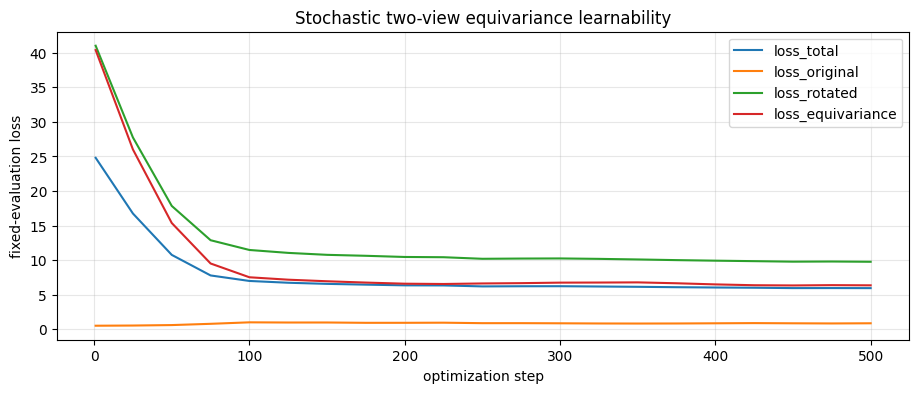

RUN_FULL_TRAINING: False (set True manually only after inspecting both supervised losses and equivariance)


In [52]:
STOCHASTIC_NUM_WINDOWS = min(BATCH_SIZE, 16)
STOCHASTIC_NUM_STEPS = 500
STOCHASTIC_PRINT_EVERY = 25
STOCHASTIC_TRAIN_SEED = TRAIN_PAIR_SEED + 200000
STOCHASTIC_EVAL_SEED = TRAIN_PAIR_SEED + 300000
STOCHASTIC_MIN_EQUIV_REDUCTION = 0.20
STOCHASTIC_MIN_ROTATED_REDUCTION = 0.20

stochastic_indices = np.linspace(0, len(train_dataset)-1, STOCHASTIC_NUM_WINDOWS, dtype=int)
stochastic_base = window_batch_to(collate_windows([train_dataset[int(i)] for i in stochastic_indices]), DEVICE, dtype=MODEL_DTYPE)
fixed_original, fixed_rotated, fixed_H, fixed_active = make_equivariant_windows(stochastic_base, generator=make_augmentation_generator(STOCHASTIC_EVAL_SEED), frame_probability=1.0)
train_generator = make_augmentation_generator(STOCHASTIC_TRAIN_SEED)
previous_state = {k: v.detach().cpu().clone() for k,v in model.state_dict().items()}
previous_mode = model.training
load_training_checkpoint(RESUME_CHECKPOINT, model=model, map_location=DEVICE, restore_rng_state=False)
small_optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)


def evaluate_fixed_equivariance():
    model.eval()
    with torch.no_grad():
        a = window_step(fixed_original).model_output
        b = window_step(fixed_rotated).model_output
        total, metrics = compute_equivariant_objective(fixed_original, a, fixed_rotated, b, fixed_H, fixed_active)
    return float(total.detach().cpu()), metrics


initial_total, initial_metrics = evaluate_fixed_equivariance()
trace = []
print("STOCHASTIC EQUIVARIANCE TEST | physical windows:", STOCHASTIC_NUM_WINDOWS, "| steps:", STOCHASTIC_NUM_STEPS)
print("Initial fixed evaluation:", {k: round(initial_metrics[k], 4) for k in ("loss_total", "loss_original", "loss_rotated", "loss_equivariance", "rotated/active_rotation_error_deg", "rotated/active_tau_error_ms")})
for step in range(1, STOCHASTIC_NUM_STEPS + 1):
    model.train()
    original, rotated, H, active = make_equivariant_windows(stochastic_base, generator=train_generator)
    small_optimizer.zero_grad(set_to_none=True)
    out_original = window_step(original).model_output
    out_rotated = window_step(rotated).model_output
    loss, _ = compute_equivariant_objective(original, out_original, rotated, out_rotated, H, active)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), GRADIENT_CLIP_NORM)
    small_optimizer.step()
    if step == 1 or step % STOCHASTIC_PRINT_EVERY == 0 or step == STOCHASTIC_NUM_STEPS:
        value, metrics = evaluate_fixed_equivariance()
        trace.append({"step":step, **metrics})
        print(f"step {step:4d}/{STOCHASTIC_NUM_STEPS} train={loss.item():.5f} eval={value:.5f} original={metrics['loss_original']:.5f} rotated={metrics['loss_rotated']:.5f} equiv={metrics['loss_equivariance']:.5f} | " + " ".join(f"{key}: eqR={metrics[f'equiv/{key}/rotation_equivariance_deg']:.2f}deg rotErr={metrics[f'rotated/{key}/rotation_error_deg']:.2f}deg" for key in CALIBRATION_KEYS), flush=True)

final_metrics = trace[-1]
equiv_fraction = final_metrics["loss_equivariance"] / max(initial_metrics["loss_equivariance"], 1e-10)
rotated_fraction = final_metrics["loss_rotated"] / max(initial_metrics["loss_rotated"], 1e-10)
original_fraction = final_metrics["loss_original"] / max(initial_metrics["loss_original"], 1e-10)
active_rotation_fraction = final_metrics["rotated/active_rotation_error_deg"] / max(initial_metrics["rotated/active_rotation_error_deg"], 1e-10)
EQUIVARIANCE_STOCHASTIC_GATE_PASSED = bool(equiv_fraction <= 1-STOCHASTIC_MIN_EQUIV_REDUCTION and rotated_fraction <= 1-STOCHASTIC_MIN_ROTATED_REDUCTION and original_fraction <= 1.05 and active_rotation_fraction <= 0.85)
print("Fixed evaluation fractions: equiv=%.3f, rotated supervised=%.3f, original supervised=%.3f, rotated ACTIVE rotation error=%.3f" % (equiv_fraction, rotated_fraction, original_fraction, active_rotation_fraction))
print("EQUIVARIANCE LEARNABILITY GATE:", "PASS" if EQUIVARIANCE_STOCHASTIC_GATE_PASSED else "FAIL/WARNING")

fig, ax = plt.subplots(figsize=(11, 4))
for name in ("loss_total", "loss_original", "loss_rotated", "loss_equivariance"):
    ax.plot([x["step"] for x in trace], [x[name] for x in trace], label=name)
ax.set(xlabel="optimization step", ylabel="fixed-evaluation loss", title="Stochastic two-view equivariance learnability")
ax.grid(alpha=0.3); ax.legend(); plt.show()

model.load_state_dict(previous_state)
model.train(previous_mode)
model.zero_grad(set_to_none=True)
del small_optimizer, previous_state, stochastic_base, fixed_original, fixed_rotated, fixed_H, fixed_active, train_generator
for name in ("original", "rotated", "H", "active", "out_original", "out_rotated", "loss"):
    if name in globals(): del globals()[name]
if DEVICE.type == "cuda": torch.cuda.empty_cache()
RUN_FULL_TRAINING = EQUIVARIANCE_STOCHASTIC_GATE_PASSED
print("RUN_FULL_TRAINING:", RUN_FULL_TRAINING, "(set True manually only after inspecting both supervised losses and equivariance)")


In [53]:

metric_names = (
    "loss_original",
    "loss_rotated",
    "loss_equivariance",
    "original/active_rotation_error_deg",
    "rotated/active_rotation_error_deg",
    "original/active_tau_error_ms",
    "rotated/active_tau_error_ms",
)

for name in metric_names:
    initial = initial_metrics[name]
    final = final_metrics[name]
    print(f"{name:42s} initial={initial:10.4f} final={final:10.4f} ratio={final / max(abs(initial), 1e-10):7.3f}")

print("\nStochastic gate:", EQUIVARIANCE_STOCHASTIC_GATE_PASSED)
print("Full training enabled:", RUN_FULL_TRAINING)


loss_original                              initial=    0.5096 final=    0.8610 ratio=  1.689
loss_rotated                               initial=   41.5758 final=    9.7630 ratio=  0.235
loss_equivariance                          initial=   40.9930 final=    6.3531 ratio=  0.155
original/active_rotation_error_deg         initial=    5.8457 final=    7.5971 ratio=  1.300
rotated/active_rotation_error_deg          initial=   36.6712 final=   23.5824 ratio=  0.643
original/active_tau_error_ms               initial=    9.8623 final=   20.0404 ratio=  2.032
rotated/active_tau_error_ms                initial=  116.9362 final=  125.3741 ratio=  1.072

Stochastic gate: False
Full training enabled: False


## 11. Single-window two-view epoch runner

In [54]:
def run_equivariant_epoch(loader, *, training: bool, generator: torch.Generator, global_step: int):
    model.train(training)
    metric_sums, num_samples = {}, 0
    start = time.perf_counter()
    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for batch_number, base in enumerate(loader, start=1):
            base = window_batch_to(base, DEVICE, dtype=MODEL_DTYPE)
            original, rotated, H, active = make_equivariant_windows(base, generator=generator)
            if training: optimizer.zero_grad(set_to_none=True)
            out_original = window_step(original).model_output
            out_rotated = window_step(rotated).model_output
            loss, metrics = compute_equivariant_objective(original, out_original, rotated, out_rotated, H, active)
            if training:
                loss.backward()
                if GRADIENT_CLIP_NORM is not None: torch.nn.utils.clip_grad_norm_(model.parameters(), GRADIENT_CLIP_NORM)
                optimizer.step()
                global_step += 1
            batch_size = next(iter(original.streams.values())).values.shape[0]
            accumulate_metrics(metric_sums, metrics, batch_size)
            num_samples += batch_size
            if training and PRINT_EVERY_BATCHES > 0 and batch_number % PRINT_EVERY_BATCHES == 0:
                print(f"batch {batch_number}/{len(loader)} total={metrics['loss_total']:.5f} original={metrics['loss_original']:.5f} rotated={metrics['loss_rotated']:.5f} equiv={metrics['loss_equivariance']:.5f}", flush=True)
    elapsed = time.perf_counter() - start
    epoch_metrics = normalize_metrics(metric_sums, num_samples)
    epoch_metrics["epoch_time_s"] = elapsed
    epoch_metrics["samples_per_s"] = num_samples / max(elapsed, 1e-9)
    return epoch_metrics, global_step


def accumulate_metrics(metric_sums, metrics, batch_size):
    for key, value in metrics.items(): metric_sums[key] = metric_sums.get(key, 0.0) + float(value) * batch_size


def normalize_metrics(metric_sums, num_samples):
    if num_samples <= 0: raise ValueError("No examples in epoch.")
    return {key: value/num_samples for key,value in metric_sums.items()}


## 12. Experiment checkpoint snapshot

In [55]:
RUN_DIR = ROOT / "runs" / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=True)
BEST_CHECKPOINT_PATH = RUN_DIR / "best.pt"
LAST_CHECKPOINT_PATH = RUN_DIR / "last.pt"
METRICS_PATH = RUN_DIR / "metrics.jsonl"
EXPERIMENT_SNAPSHOT = {
    "run_name": RUN_NAME, "architecture": "PooledCalibrationModel", "model_config": model_config,
    "windowing_config": windowing_config, "rig_calibration": rig_calibration, "measurement_dim": MEASUREMENT_DIM,
    "calibration_keys": CALIBRATION_KEYS,
    "sequence_split": {"train": tuple(TRAIN_NAMES), "validation": tuple(VAL_NAMES), "test": tuple(TEST_NAMES)},
    "paired_prior_training": False,
    "pair_sampling_strategy": "single_truncated_student_t_one_calibration_per_sample",
    "pair_prior_config": pair_prior_config, "context_augmentation_config": context_augmentation_config,
    "equivariance_loss_weight": EQUIVARIANCE_LOSS_WEIGHT, "paired_view_probability": COMMON_BODY_FRAME_PROBABILITY,
    "paired_view_transform": "shared_left_rotation_only_SO3",
    "training_objective": "two_supervised_views_plus_adjoint_equivariance",
    "equivariance_components": "rotation_and_translation_adjoint_plus_tau_identity",
    "pair_rotation_max_rad": PAIR_ROTATION_MAX_RAD, "pair_time_offset_max_s": PAIR_TIME_OFFSET_MAX_S,
    "initialization_checkpoint": str(RESUME_CHECKPOINT), "checkpoint_selection_metric": "loss_regular",
    "true_calibration_rotation_max_rad": TRUE_CALIBRATION_ROTATION_MAX_RAD,
    "true_calibration_time_offset_max_s": TRUE_CALIBRATION_TIME_OFFSET_MAX_S,
    "seeds": {"random": RANDOM_SEED, "train": TRAIN_PAIR_SEED, "validation": VALIDATION_PAIR_SEED, "test": TEST_PAIR_SEED},
}
LOGGER_EXPERIMENT_SNAPSHOT = {
    "run_name": RUN_NAME, "architecture": "PooledCalibrationModel", "calibration_keys": list(CALIBRATION_KEYS),
    "training_objective": EXPERIMENT_SNAPSHOT["training_objective"], "equivariance_loss_weight": EQUIVARIANCE_LOSS_WEIGHT,
    "paired_view_probability": COMMON_BODY_FRAME_PROBABILITY, "prior_rotation_max_deg": float(np.rad2deg(PAIR_ROTATION_MAX_RAD)),
    "true_calibration_rotation_max_deg": float(np.rad2deg(TRUE_CALIBRATION_ROTATION_MAX_RAD)),
    "source_checkpoint": str(RESUME_CHECKPOINT), "checkpoint_selection_metric": "loss_regular",
}
train_equiv_generator = make_augmentation_generator(TRAIN_PAIR_SEED)


## 13. Initialize from pretrained weights (fresh optimizer, no BPTT resume)

In [56]:
start_epoch = 0
global_step = 0
best_validation_loss = float("inf")

if RESUME_CHECKPOINT is not None:
    checkpoint = load_training_checkpoint(
        RESUME_CHECKPOINT,
        model=model,
        # Initialize model weights only. The optimizer, scheduler and RNG state are fresh.
        # optimizer=optimizer,
        # scheduler=scheduler,
        map_location=DEVICE,
        restore_rng_state=False,
    )
    # start_epoch = int(checkpoint.get("epoch", 0))
    # global_step = int(checkpoint.get("global_step", 0))
    # best_validation_loss = float(checkpoint.get("extra_state", {}).get("best_validation_loss", float("inf")))

    print("Initialized model weights from:", RESUME_CHECKPOINT)
    print("start epoch:", start_epoch)
    print("global step:", global_step)


Initialized model weights from: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_paired_002.16_correction_only/best.pt
start epoch: 0
global step: 0


## 14. Full single-window training

Runs only if the small-set test supports both frame consistency and calibration accuracy. To override intentionally, set `RUN_FULL_TRAINING = True` **after** the learnability test. Checkpoints are chosen by *both-view supervised loss*, not by equivariance loss alone.

In [69]:
torch.cuda.empty_cache()

In [64]:
history = []
print("Single-window equivariance gate:", "PASS" if RUN_FULL_TRAINING else "NOT PASSED: training disabled")
RUN_FULL_TRAINING=True
if RUN_FULL_TRAINING:
    if DEVICE.type == "cuda": torch.cuda.empty_cache()
    with MetricsLogger(METRICS_PATH, append=False) as logger:
        logger.log_config(model_config, name="model_config")
        logger.log_config(context_augmentation_config, name="context_augmentation_config")
        logger.log_config(pair_prior_config, name="prior_config")
        logger.log_config(LOGGER_EXPERIMENT_SNAPSHOT, name="experiment")
        for epoch in range(start_epoch, NUM_EPOCHS):
            train_metrics, global_step = run_equivariant_epoch(train_loader, training=True, generator=train_equiv_generator, global_step=global_step)
            val_generator = make_augmentation_generator(VALIDATION_PAIR_SEED)
            val_metrics, _ = run_equivariant_epoch(val_loader, training=False, generator=val_generator, global_step=global_step)
            scheduler.step(val_metrics["loss_regular"])
            lr = optimizer.param_groups[0]["lr"]
            row = {"epoch": epoch+1, "global_step":global_step, "learning_rate":lr, **{f"train/{k}":v for k,v in train_metrics.items()}, **{f"val/{k}":v for k,v in val_metrics.items()}}
            history.append(row)
            logger.log_metrics({**train_metrics, "learning_rate":lr}, split="train", epoch=epoch+1, step=global_step)
            logger.log_metrics(val_metrics, split="validation", epoch=epoch+1, step=global_step)
            print(f"Epoch {epoch+1}/{NUM_EPOCHS}: train regular={train_metrics['loss_regular']:.5f} (orig={train_metrics['loss_original']:.5f}, rotated={train_metrics['loss_rotated']:.5f}), equiv={train_metrics['loss_equivariance']:.5f} | val regular={val_metrics['loss_regular']:.5f} (orig={val_metrics['loss_original']:.5f}, rotated={val_metrics['loss_rotated']:.5f}), equiv={val_metrics['loss_equivariance']:.5f}, active={val_metrics['equiv/active_fraction']:.2f} lr={lr:.2e}", flush=True)
            if val_metrics["loss_regular"] < best_validation_loss:
                best_validation_loss = val_metrics["loss_regular"]
                save_training_checkpoint(BEST_CHECKPOINT_PATH, model=model, optimizer=optimizer, scheduler=scheduler, epoch=epoch+1, global_step=global_step, metrics=val_metrics, generators={"train_shuffle":train_shuffle_generator, "train_pair":train_equiv_generator}, extra_state={"best_validation_loss":best_validation_loss, "experiment":EXPERIMENT_SNAPSHOT})
                print("Saved best checkpoint.")
            if (epoch+1) % CHECKPOINT_EVERY_EPOCHS == 0 or epoch+1 == NUM_EPOCHS:
                save_training_checkpoint(LAST_CHECKPOINT_PATH, model=model, optimizer=optimizer, scheduler=scheduler, epoch=epoch+1, global_step=global_step, metrics=val_metrics, generators={"train_shuffle":train_shuffle_generator, "train_pair":train_equiv_generator}, extra_state={"best_validation_loss":best_validation_loss, "experiment":EXPERIMENT_SNAPSHOT})
            gc.collect()
            if DEVICE.type == "cuda": torch.cuda.empty_cache()
else:
    print("Full training skipped. Review the stochastic diagnostic before overriding RUN_FULL_TRAINING.")


Single-window equivariance gate: NOT PASSED: training disabled
Epoch 1/200: train regular=9.68940 (orig=1.23541, rotated=18.14339), equiv=17.17165 | val regular=6.82678 (orig=1.24850, rotated=12.40507), equiv=8.96498, active=0.91 lr=1.00e-05
Saved best checkpoint.
Epoch 2/200: train regular=6.31375 (orig=1.25866, rotated=11.36884), equiv=8.34700 | val regular=6.66280 (orig=1.16960, rotated=12.15600), equiv=8.82326, active=0.91 lr=1.00e-05
Saved best checkpoint.
Epoch 3/200: train regular=6.36091 (orig=1.34892, rotated=11.37290), equiv=8.46368 | val regular=6.54484 (orig=1.16067, rotated=11.92900), equiv=8.66547, active=0.91 lr=1.00e-05
Saved best checkpoint.
Epoch 4/200: train regular=6.16694 (orig=1.38232, rotated=10.95156), equiv=7.93644 | val regular=6.37114 (orig=1.20952, rotated=11.53276), equiv=8.46970, active=0.91 lr=1.00e-05
Saved best checkpoint.
Epoch 5/200: train regular=5.88889 (orig=1.41876, rotated=10.35902), equiv=7.38714 | val regular=6.00416 (orig=1.20674, rotated=10.8

KeyboardInterrupt: 

## 15. Checkpoint snapshot verification

In [65]:
from obscalib.training.checkpoint import read_training_checkpoint
for checkpoint_path in (BEST_CHECKPOINT_PATH, LAST_CHECKPOINT_PATH):
    if not checkpoint_path.is_file():
        print("Not yet created:", checkpoint_path)
        continue
    saved = read_training_checkpoint(checkpoint_path, map_location="cpu")
    snapshot = (saved.get("extra_state") or {}).get("experiment", {})
    assert snapshot.get("run_name") == RUN_NAME
    assert snapshot.get("training_objective") == "two_supervised_views_plus_adjoint_equivariance"
    assert isinstance(snapshot.get("model_config"), PooledCalibrationModelConfig)
    assert isinstance(snapshot.get("windowing_config"), WindowingConfig)
    print("Verified:", checkpoint_path.name, "epoch:", saved.get("epoch"))


Verified: best.pt epoch: 191
Verified: last.pt epoch: 192


## 16. Training curves: supervised and equivariance errors separately

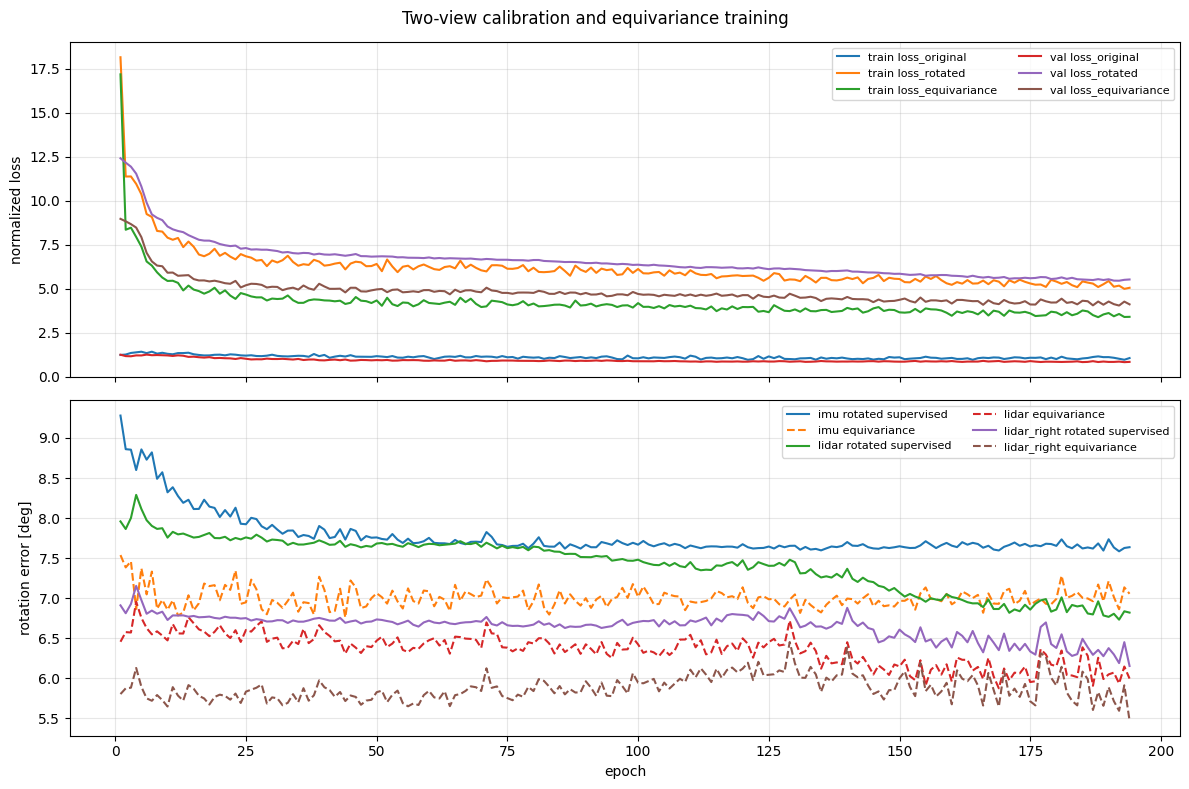

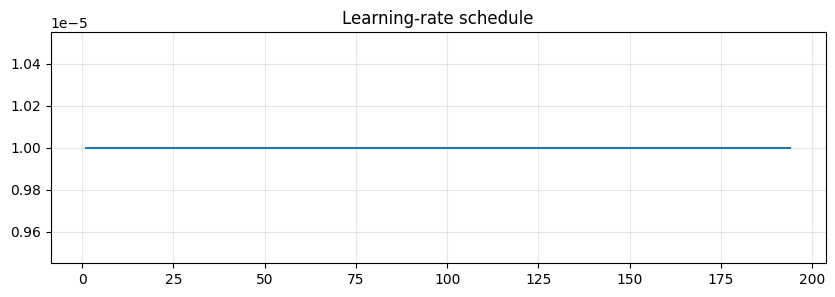

In [66]:
if history:
    epochs = [r["epoch"] for r in history]
    fig, axes = plt.subplots(2,1,figsize=(12,8),sharex=True)
    for phase in ("train", "val"):
        for key in ("loss_original", "loss_rotated", "loss_equivariance"):
            axes[0].plot(epochs, [r[f"{phase}/{key}"] for r in history], label=f"{phase} {key}")
    axes[0].set_ylabel("normalized loss");axes[0].grid(alpha=0.3);axes[0].legend(ncol=2,fontsize=8)
    for key in CALIBRATION_KEYS:
        axes[1].plot(epochs, [r[f"val/rotated/{key}/rotation_error_deg"] for r in history],label=f"{key} rotated supervised")
        axes[1].plot(epochs, [r[f"val/equiv/{key}/rotation_equivariance_deg"] for r in history],linestyle="--",label=f"{key} equivariance")
    axes[1].set(xlabel="epoch",ylabel="rotation error [deg]");axes[1].grid(alpha=0.3);axes[1].legend(ncol=2,fontsize=8)
    fig.suptitle("Two-view calibration and equivariance training");fig.tight_layout();plt.show()
    plt.figure(figsize=(10,3));plt.plot(epochs,[r["learning_rate"] for r in history]);plt.title("Learning-rate schedule");plt.grid(alpha=0.3);plt.show()


## 17. Held-out evaluation of the best checkpoint and source model

In [70]:
COMPARE_TO_SOURCE_CHECKPOINT = True

def evaluate_matched_test():
    gen = make_augmentation_generator(TEST_PAIR_SEED + 901)
    result, _ = run_equivariant_epoch(test_loader, training=False, generator=gen, global_step=0)
    return result


def print_evaluation(label, m):
    print(f"{label}: total={m['loss_total']:.4f}, regular={m['loss_regular']:.4f}, original={m['loss_original']:.4f}, rotated={m['loss_rotated']:.4f}, equiv={m['loss_equivariance']:.4f}")
    for key in CALIBRATION_KEYS:
        print(f"   {key:12s} original rot={m[f'original/{key}/rotation_error_deg']:.2f}deg, rotated rot={m[f'rotated/{key}/rotation_error_deg']:.2f}deg, equiv={m[f'equiv/{key}/rotation_equivariance_deg']:.2f}deg, original tau={m[f'original/{key}/time_offset_error_ms']:.2f}ms, rotated tau={m[f'rotated/{key}/time_offset_error_ms']:.2f}ms")

if BEST_CHECKPOINT_PATH.is_file():
    load_training_checkpoint(BEST_CHECKPOINT_PATH, model=model, map_location=DEVICE, restore_rng_state=False)
    new_metrics = evaluate_matched_test()
    print_evaluation("New checkpoint",new_metrics)
    if COMPARE_TO_SOURCE_CHECKPOINT:
        load_training_checkpoint(RESUME_CHECKPOINT, model=model, map_location=DEVICE, restore_rng_state=False)
        try:
            source_metrics = evaluate_matched_test()
            print_evaluation("Pretrained source", source_metrics)
            print("Change in rotated supervised loss: %+.1f%%" % (100*(new_metrics["loss_rotated"]/source_metrics["loss_rotated"] -1)))
            print("Change in equivariance loss: %+.1f%%" % (100*(new_metrics["loss_equivariance"]/max(source_metrics["loss_equivariance"],1e-10) -1)))
        finally:
            load_training_checkpoint(BEST_CHECKPOINT_PATH, model=model, map_location=DEVICE, restore_rng_state=False)
else:
    print("Best checkpoint absent. Train first or inspect the fixed stochastic diagnostic.")


New checkpoint: total=3.4419, regular=3.0400, original=0.7497, rotated=5.3303, equiv=4.0182
   imu          original rot=2.20deg, rotated rot=7.99deg, equiv=7.37deg, original tau=2.65ms, rotated tau=7.12ms
   lidar        original rot=2.58deg, rotated rot=5.96deg, equiv=5.31deg, original tau=6.51ms, rotated tau=11.39ms
   lidar_right  original rot=2.31deg, rotated rot=6.33deg, equiv=5.83deg, original tau=6.72ms, rotated tau=10.94ms
Pretrained source: total=27.7166, regular=22.7466, original=0.6362, rotated=44.8570, equiv=49.6996
   imu          original rot=1.55deg, rotated rot=39.30deg, equiv=43.49deg, original tau=2.61ms, rotated tau=87.33ms
   lidar        original rot=2.35deg, rotated rot=22.18deg, equiv=24.08deg, original tau=6.01ms, rotated tau=74.49ms
   lidar_right  original rot=2.17deg, rotated rot=21.04deg, equiv=23.21deg, original tau=6.20ms, rotated tau=70.04ms
Change in rotated supervised loss: -88.1%
Change in equivariance loss: -91.9%


## 18. Paired-view correction and equivariance scatter

The two views have the same physical target. The rotated-view predicted correction is brought back to the original common frame by \(G^\top\) for comparison. Plots show both frame-wise supervised errors **and** differences after compensating for \(G\).

original_error_deg        rotated_error_deg         \
                          mean median              mean median   
sensor                                                           
imu                      1.706  0.148             6.600  0.330   
lidar                    2.067  0.275             7.069  0.926   
lidar_right              2.905  0.289             7.542  0.845   

            equivariance_error_deg        original_tau_error_ms         \
                              mean median                  mean median   
sensor                                                                   
imu                          5.797  0.385                 1.785  0.608   
lidar                        5.985  0.808                 7.931  2.460   
lidar_right                  6.188  0.872                 6.828  2.656   

            rotated_tau_error_ms        tau_equivariance_ms         
                            mean median                mean median  
sensor                                                              
imu                        6.854  2.289               7.354  2.440  
lidar                     11.860  6.271               8.860  5.375  
lidar_right               12.311  4.397              11.126  5.432

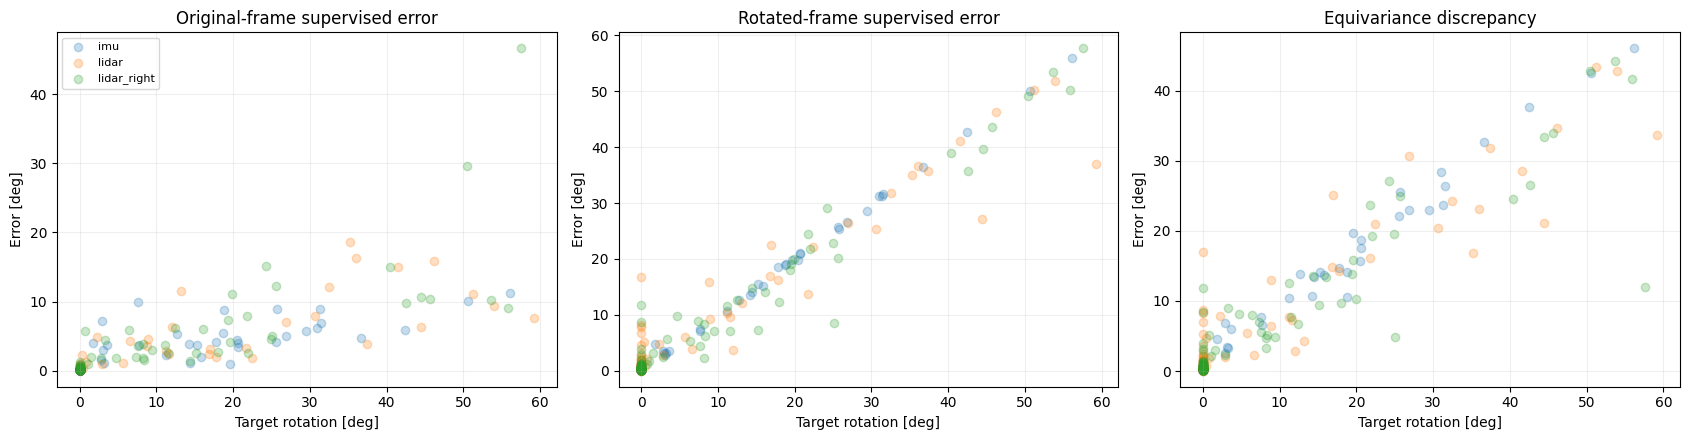

In [71]:
VIS_SEQUENCE_NAME = "Urban38"
VIS_START_WINDOW = 0
VIS_NUM_WINDOWS = 100
VIS_BATCH_SIZE = 16
sequence_indices = [i for i in range(len(test_dataset)) if test_dataset.sequence_name_for_window(i) == VIS_SEQUENCE_NAME]
selected_indices = sequence_indices[VIS_START_WINDOW:VIS_START_WINDOW+VIS_NUM_WINDOWS]
if not selected_indices: raise ValueError("No selected held-out windows.")


def collect_equivariant_predictions(dataset, indices, batch_size=VIS_BATCH_SIZE, seed=VISUALIZATION_PAIR_SEED):
    model.eval()
    generator=make_augmentation_generator(seed)
    rows=[]
    with torch.no_grad():
        for start in range(0,len(indices),batch_size):
            batch=window_batch_to(collate_windows([dataset[int(j)] for j in indices[start:start+batch_size]]),DEVICE,dtype=MODEL_DTYPE)
            a,b,H,active=make_equivariant_windows(batch,generator=generator,frame_probability=1.0)
            pa,pb=window_step(a).model_output,window_step(b).model_output
            G=H[:,:3,:3]
            for key in CALIBRATION_KEYS:
                target_xi,target_tau=correction_target(a,key)
                xa=pa.predictions[key].delta_xi
                xb=pb.predictions[key].delta_xi
                xa_in_b=rotate_twist(xa,G)
                xb_in_a=rotate_twist(xb,G.transpose(1,2))
                for i in range(xa.shape[0]):
                    rows.append({"window":int(indices[start+i]),"sensor":key,"target_rotation_deg":float(torch.rad2deg(torch.linalg.vector_norm(target_xi[i,:3])).cpu()),"original_error_deg":float(torch.rad2deg(torch.linalg.vector_norm(xa[i,:3]-target_xi[i,:3])).cpu()),"rotated_error_deg":float(torch.rad2deg(torch.linalg.vector_norm(xb_in_a[i,:3]-target_xi[i,:3])).cpu()),"equivariance_error_deg":float(torch.rad2deg(torch.linalg.vector_norm(xb[i,:3]-xa_in_b[i,:3])).cpu()),"original_tau_error_ms":float((1000*(pa.predictions[key].delta_tau[i]-target_tau[i]).abs()).cpu()),"rotated_tau_error_ms":float((1000*(pb.predictions[key].delta_tau[i]-target_tau[i]).abs()).cpu()),"tau_equivariance_ms":float((1000*(pb.predictions[key].delta_tau[i]-pa.predictions[key].delta_tau[i]).abs()).cpu())})
    return __import__('pandas').DataFrame(rows)

if BEST_CHECKPOINT_PATH.is_file():
    load_training_checkpoint(BEST_CHECKPOINT_PATH,model=model,map_location=DEVICE,restore_rng_state=False)
    vis_equiv = collect_equivariant_predictions(test_dataset, selected_indices)
    vis_equiv.to_csv(RUN_DIR/"heldout_frame_equivariance.csv",index=False)
    display(vis_equiv.groupby("sensor")[["original_error_deg","rotated_error_deg","equivariance_error_deg","original_tau_error_ms","rotated_tau_error_ms","tau_equivariance_ms"]].agg(["mean","median"]).round(3))
    fig,axes=plt.subplots(1,3,figsize=(17,4.5))
    for key,group in vis_equiv.groupby("sensor"):
        axes[0].scatter(group.target_rotation_deg,group.original_error_deg,alpha=.25,label=key)
        axes[1].scatter(group.target_rotation_deg,group.rotated_error_deg,alpha=.25,label=key)
        axes[2].scatter(group.target_rotation_deg,group.equivariance_error_deg,alpha=.25,label=key)
    for ax,title in zip(axes,("Original-frame supervised error","Rotated-frame supervised error","Equivariance discrepancy")):
        ax.set(xlabel="Target rotation [deg]",ylabel="Error [deg]",title=title);ax.grid(alpha=.2)
    axes[0].legend(fontsize=8);fig.tight_layout();plt.show()
else:
    print("Visualization skipped until a trained checkpoint is available.")


## 19. Exact-truth fixed-point diagnostic

A model can reduce equivariance loss by predicting zero for both views. Therefore retain the pretrained fixed-point test: nominally correct calibration should receive nearly zero corrections. This is an extra check, not a substitute for perturbed-calibration accuracy.

In [72]:
FIXED_POINT_NUM_WINDOWS = min(100, len(sequence_indices))
fixed_point_positions = np.unique(np.linspace(0, len(sequence_indices) - 1, FIXED_POINT_NUM_WINDOWS).round().astype(int))
fixed_point_indices = np.asarray(sequence_indices)[fixed_point_positions]

fixed_point_results = {calibration_key: {"delta_xi": [], "delta_tau": []} for calibration_key in CALIBRATION_KEYS}

model.eval()

with torch.no_grad():
    for dataset_index in fixed_point_indices:
        window = window_batch_to(collate_windows([test_dataset[int(dataset_index)]]), DEVICE, dtype=MODEL_DTYPE)
        exact_true_calibration = {calibration_key: CalibrationState(transform=state.transform.clone(), time_offset=state.time_offset.clone()) for calibration_key, state in window.current_calibration.items()}
        result = window_step(window, calibration=exact_true_calibration)

        for calibration_key, prediction in result.model_output.predictions.items():
            fixed_point_results[calibration_key]["delta_xi"].append(prediction.delta_xi[0].detach().cpu())
            fixed_point_results[calibration_key]["delta_tau"].append(prediction.delta_tau[0, 0].detach().cpu())

for calibration_key in CALIBRATION_KEYS:
    fixed_point_results[calibration_key]["delta_xi"] = torch.stack(fixed_point_results[calibration_key]["delta_xi"]).numpy()
    fixed_point_results[calibration_key]["delta_tau"] = torch.stack(fixed_point_results[calibration_key]["delta_tau"]).numpy()

component_names = ("phi_x", "phi_y", "phi_z", "rho_x", "rho_y", "rho_z", "tau")

print("=" * 120)
print("EXACT-TRUTH FIXED-POINT DIAGNOSTIC")
print("=" * 120)

for calibration_key in CALIBRATION_KEYS:
    result = fixed_point_results[calibration_key]
    prediction = np.concatenate([result["delta_xi"], result["delta_tau"][:, None]], axis=1)

    print(calibration_key)
    print(f"{'component':8s} {'mean':>16s} {'mean |x|':>16s} {'RMSE':>16s} {'std':>16s} {'range':>16s}")

    for component_index, component_name in enumerate(component_names):
        values = prediction[:, component_index]

        if component_index < 3:
            values, unit = np.rad2deg(values), "deg"
        elif component_index < 6:
            values, unit = 100.0 * values, "cm"
        else:
            values, unit = 1000.0 * values, "ms"

        mean = np.mean(values)
        mean_abs = np.mean(np.abs(values))
        rmse = np.sqrt(np.mean(values ** 2))
        std = np.std(values)
        value_range = np.max(values) - np.min(values)

        print(f"{component_name:8s} {mean:+12.6f} {unit:3s} {mean_abs:12.6f} {unit:3s} {rmse:12.6f} {unit:3s} {std:12.6f} {unit:3s} {value_range:12.6f} {unit:3s}")

    print()


EXACT-TRUTH FIXED-POINT DIAGNOSTIC
imu
component             mean         mean |x|             RMSE              std            range
phi_x       -0.102141 deg     0.244283 deg     0.416486 deg     0.403767 deg     3.437237 deg
phi_y       +0.077601 deg     0.277716 deg     0.461578 deg     0.455008 deg     3.928264 deg
phi_z       +0.252579 deg     0.713503 deg     1.386021 deg     1.362813 deg    11.073228 deg
rho_x       +0.010780 cm      0.010780 cm      0.011053 cm      0.002443 cm      0.013551 cm 
rho_y       +0.002056 cm      0.004796 cm      0.006043 cm      0.005682 cm      0.024048 cm 
rho_z       +0.005761 cm      0.007055 cm      0.009397 cm      0.007425 cm      0.033437 cm 
tau         -0.672828 ms      2.515394 ms      3.257255 ms      3.187007 ms     17.291307 ms 

lidar
component             mean         mean |x|             RMSE              std            range
phi_x       -0.265503 deg     0.517317 deg     0.986385 deg     0.949981 deg     7.494292 deg
phi_y       

## 20. Interpretation and next evaluation

- **Equivariance falls and rotated-view accuracy improves:** evidence that the new objective trains the missing common-frame symmetry.
- **Equivariance falls but rotated-view accuracy does not:** possible trivial agreement between equally wrong predictions; do not accept as success.
- **Original-view accuracy degrades:** the added objective may be overpowering the supervised signal. Consider lowering `EQUIVARIANCE_LOSS_WEIGHT`.
- **Neither falls:** inspect whether canonicalization and target rotation match the tested symmetry, then try a curriculum on the *angle of G* rather than adjusting the 0.9 probability.

For fair comparison, take this notebook's best checkpoint and the original checkpoint into notebook 37's KAIST frame-equivariance test and NewCollege single-sensor evaluation. Neither observability supervision nor BPTT is used here.

In [73]:
print("Run:", RUN_NAME)
print("Source checkpoint:", RESUME_CHECKPOINT)
print("Regime: independent 5-second windows, one prior, two common-frame views (NO BPTT)")
print("Rotated-view probability:", COMMON_BODY_FRAME_PROBABILITY)
print("Equivariance weight:", EQUIVARIANCE_LOSS_WEIGHT)
print("Stochastic gate passed:", EQUIVARIANCE_STOCHASTIC_GATE_PASSED)
print("Best checkpoint:", BEST_CHECKPOINT_PATH, "exists:", BEST_CHECKPOINT_PATH.is_file())
if history:
    best_row=min(history,key=lambda r:r['val/loss_regular'])
    print("Best validation epoch:",best_row['epoch'], "regular:",best_row['val/loss_regular'], "equiv:",best_row['val/loss_equivariance'])


Run: kaist_pooled_calibration_paired_002.20_common_frame_equivariance
Source checkpoint: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_paired_002.16_correction_only/best.pt
Regime: independent 5-second windows, one prior, two common-frame views (NO BPTT)
Rotated-view probability: 0.9
Equivariance weight: 0.1
Stochastic gate passed: False
Best checkpoint: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_paired_002.20_common_frame_equivariance/best.pt exists: True
Best validation epoch: 191 regular: 3.1482495006762052 equiv: 4.120478281278929


In [74]:
torch.cuda.empty_cache()